# 03 · Arranque, ciclo principal, MQTT y hora

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](02_librerias_constantes_y_estado.ipynb) · [Siguiente](04_sensores_json_y_pantalla.ipynb)

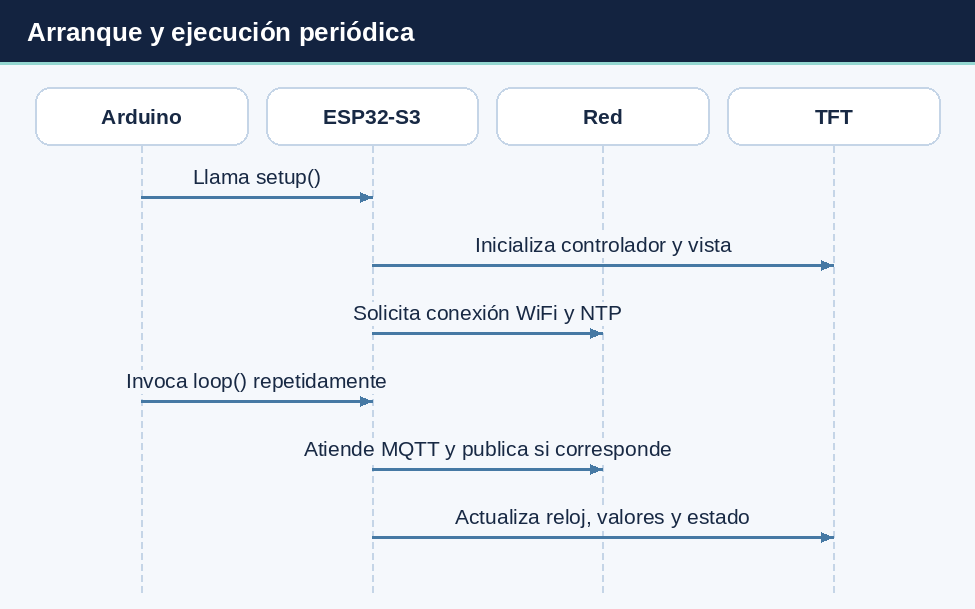

## `setup`


**Parámetros:** ninguno. **Retorno:** `void`. Arduino la llama una vez por arranque.
Inicializa Serial a 115200, configura pantalla, monta LittleFS sin formatearlo y carga config.
Abre NVS en el espacio `csv-queue` en modo lectura/escritura (`false`) y recupera `offset`,
con 0 como predeterminado. Inicializa DHT y ADC, inicia WiFi estación y solicita sincronización NTP.
Prepara el cliente MQTT y activa `isInitialized` al final.

`LittleFS.begin(false)` significa que no debe formatear automáticamente si falla el montaje.
Si alguna inicialización requerida falla, `return` deja `isInitialized=false`. Aunque `loop()`
sigue ejecutándose, no procesa sensores ni MQTT. El programa no reintenta automáticamente ese
error de arranque. `WiFi.begin` inicia la conexión; no espera aquí a que esté establecida.

Argumentos relevantes: `setRotation(1)` selecciona orientación, `setTextColor(TFT_WHITE,TFT_BLACK)`
configura primer plano y fondo, `setTextSize(2)` escala texto. `analogReadResolution(12)` selecciona
resolución ADC. `configTime(-6*3600,0,...)` usa UTC−06:00 fijo, sin horario estacional.
`setServer(host,port)` configura broker; `setBufferSize(1024)` reserva hasta ese tamaño para paquetes
MQTT (incluye cabeceras, no solo payload); `setSocketTimeout(1)` usa segundos.
`setCallback(onMqttMessage)` registra una función, no la ejecuta en ese momento.

Al final, `drawDisplay()` dibuja el encabezado y las tarjetas. `updateDisplay(NAN, NAN, NAN)` inicia las cifras como faltantes hasta que exista una muestra.

```cpp
void setup() {
    Serial.begin(115200);

    Serial.println("Iniciando pantalla ST7789...");
    Serial.printf("TFT: MOSI=%d, SCLK=%d, CS=%d, DC=%d, RST=%d\n", TFT_MOSI, TFT_SCLK, TFT_CS,
                  TFT_DC, TFT_RST);
    display.init();
    Serial.println("Inicializacion TFT terminada");
    display.setRotation(1);
    display.fillScreen(TFT_BLACK);
    display.setTextColor(TFT_WHITE, TFT_BLACK);
    display.setTextSize(2);
    display.println("Iniciando...");

    // No formatear automaticamente: conserva los registros ante errores.
    if (!LittleFS.begin(false)) {
        Serial.println("ERROR: no se pudo montar LittleFS");
        display.setTextColor(TFT_RED, TFT_BLACK);
        display.println("Error LittleFS");
        return;
    }
    if (!loadConfiguration()) {
        return;
    }

    if (!queuePreferences.begin("csv-queue", false)) {
        Serial.println("ERROR: no se pudo abrir el estado del CSV");
        return;
    }
    confirmedCsvOffset = queuePreferences.getULong("offset", 0);
    dhtSensor.begin();
    analogReadResolution(12);
    analogSetPinAttenuation(PIN_MQ135, ADC_11db);

    WiFi.mode(WIFI_STA);
    WiFi.begin(configuration["SSID"].as<const char *>(), configuration["PASS"].as<const char *>());
    configTime(-6 * 3600, 0, "pool.ntp.org", "time.nist.gov");

    mqttClient.setServer(configuration["MQTT_HOST"].as<const char *>(),
                         configuration["MQTT_PORT"] | 1883);
    mqttClient.setBufferSize(1024);
    mqttClient.setSocketTimeout(1);
    mqttClient.setCallback(onMqttMessage);

    drawDisplay();
    updateDisplay(NAN, NAN, NAN);
    isInitialized = true;
}
```

## `loop`


**Parámetros:** ninguno. **Retorno:** `void`. Arduino la invoca repetidamente.
Si no terminó el arranque espera 10 ms y sale de esa iteración. Mantiene la conexión, atiende
`mqttClient.loop()` y comprueba el plazo de muestreo. Después intenta reenviar CSV, actualiza el reloj y el estado MQTT de la TFT, y cede 2 ms.

`millis() - lastSampleAt >= SAMPLE_INTERVAL_MS` compara tiempo transcurrido; la resta sin signo
permite tratar el desbordamiento periódico de `millis()` para estos intervalos pequeños. No se
compara una hora de calendario. Los 2 segundos son un intervalo mínimo aproximado: ADC, DHT,
archivo y red consumen tiempo y pueden bloquear. No se generan muestras atrasadas para recuperar
un período perdido; `lastSampleAt` toma el tiempo actual.

```cpp
void loop() {
    if (!isInitialized) {
        delay(10);
        return;
    }

    maintainMqttConnection();
    mqttClient.loop();

    if (millis() - lastSampleAt >= SAMPLE_INTERVAL_MS) {
        lastSampleAt = millis();
        sampleAndPublish();
    }

    publishPendingCsv();
    updateClock();
    updateMqttStatus();
    delay(2);
}
```

## `loadConfiguration`


**Parámetros:** ninguno. **Retorno:** `bool`: verdadero si abrió y deserializó configuración y
las claves SSID, PASS y MQTT_HOST son texto. Lee `/config.json` con `LittleFS.open(ruta,"r")`.
`deserializeJson(configuration,file)` llena el documento y devuelve un error evaluable como booleano.

El OR encadenado detiene validaciones innecesarias. Si falla imprime diagnóstico en Serial y pantalla.
No valida aquí el rango del puerto ni todas las credenciales. MQTT_PORT usa 1883 si no obtiene el
valor esperado; la plantilla debe editarse para poner un número real, no `"broker's port"`.
El objeto `File` local se libera al salir. El documento global conserva los valores.

```cpp
bool loadConfiguration() {
    File file = LittleFS.open("/config.json", "r");
    if (!file || deserializeJson(configuration, file) ||
        !configuration["SSID"].is<const char *>() || !configuration["PASS"].is<const char *>() ||
        !configuration["MQTT_HOST"].is<const char *>()) {
        Serial.println("Revisar config.json: SSID, PASS, MQTT_HOST");
        display.println("Error config.json");
        return false;
    }
    return true;
}
```

## `maintainMqttConnection`


**Parámetros:** ninguno. **Retorno:** `void`. Se llama desde `loop()`.
Lee `connected()`, compara con `wasMqttConnected` e informa una transición de conectado a desconectado.
No intenta reconectar más de una vez cada 5000 ms. Si WiFi está caído pide `WiFi.reconnect()` y retorna.

El firmware se conecta al broker sin usuario ni contraseña MQTT; el broker debe aceptar conexiones anónimas.

La llamada `connect(DEVICE_ID, statusTopic.c_str(), 1, true, "desconectado")`
recibe: ID del cliente, topic de Last Will, QoS del Will 1, retención del Will verdadera
y mensaje del Will. El Will lo emite el broker cuando detecta la pérdida no limpia de la conexión;
no es una notificación instantánea de todo corte. Un `disconnect()` limpio no dispara ese Will.

Después se suscribe al ACK con QoS solicitado 1. Si no puede enviar la suscripción, desconecta y sale.
El booleano de `subscribe()` no es una validación posterior de permisos SUBACK por esta función.
Publica `conectado` con retención verdadera y registra el estado local. No configura TLS.

```cpp
void maintainMqttConnection() {
    const bool connected = mqttClient.connected();
    if (wasMqttConnected && !connected) {
        Serial.println("Evento: MQTT desconectado; guardando CSV");
    }
    wasMqttConnected = connected;
    if (connected || millis() - lastConnectionAttemptAt < CONNECTION_RETRY_INTERVAL_MS) {
        return;
    }
    lastConnectionAttemptAt = millis();
    if (WiFi.status() != WL_CONNECTED) {
        WiFi.reconnect();
        return;
    }
    if (mqttClient.connect(DEVICE_ID, statusTopic.c_str(), 1, true,
                           "desconectado")) {
        if (!mqttClient.subscribe(acknowledgmentTopic.c_str(), 1)) {
            mqttClient.disconnect();
            return;
        }
        mqttClient.publish(statusTopic.c_str(), "conectado", true);
        Serial.println("Evento: MQTT conectado");
        wasMqttConnected = true;
    }
}
```

## `onMqttMessage`


**Parámetros:** `char *topic`, nombre recibido; `byte *payload`, bytes del cuerpo;
`unsigned int length`, número de bytes válidos. **Retorno:** `void`.
PubSubClient la llama al atender un mensaje; no es una interrupción de hardware.

Ignora otros topics o mensajes cuando no hay registro pendiente. Reconstruye el ID byte por byte,
sin exigir que payload termine en cero. Si coincide con `pendingRecordId`, escribe el final de esa
fila en NVS mediante `putULong("offset", pendingCsvEndOffset)`. Solo si se escribieron los 4 bytes de
`uint32_t` actualiza el cursor RAM y vacía el ID pendiente. Si falla, mantiene la fila para reintentar.
No borra aquí el CSV: eso se decide en `publishPendingCsv()` cuando el cursor alcanza su final.

```cpp
void onMqttMessage(char *topic, byte *payload, unsigned int length) {
    if (String(topic) != acknowledgmentTopic || pendingRecordId.isEmpty()) {
        return;
    }
    String recordId;
    for (unsigned int i = 0; i < length; ++i) {
        recordId += char(payload[i]);
    }
    // Persistir el avance solo tras la confirmacion del conversor.
    if (recordId == pendingRecordId &&
        queuePreferences.putULong("offset", pendingCsvEndOffset) == sizeof(uint32_t)) {
        confirmedCsvOffset = pendingCsvEndOffset;
        pendingRecordId = "";
    }
}
```

## `getCurrentTimestamp`


**Parámetros:** ninguno. **Retorno:** `String` ISO 8601 con desplazamiento fijo −06:00, o vacío.
`time(nullptr)` obtiene el tiempo de sistema; el umbral 1700000000 descarta una hora que todavía
parece no sincronizada. Es una comprobación simple, no una prueba de autenticidad de NTP.
`localtime_r(&now,&localTime)` convierte a componentes locales usando la configuración de zona.
`strftime(buffer,sizeof(buffer),formato,&localTime)` escribe como máximo la capacidad del arreglo.

`%Y`, `%m`, `%d`, `%H`, `%M`, `%S` significan año, mes, día, hora, minuto y segundo. La `T` y
`-06:00` son literales. Antes de sincronizar no se inventa la fecha: JSON lleva null y CSV vacío.
La hora que faltó cuando se guardó una lectura no se reconstruye más tarde.

`getLocalReadingTime()` aplica la validación a un `time_t`. `updateClock()` y `getCurrentTimestamp()` la usan para decidir qué representar cuando todavía falta NTP.

```cpp
String getCurrentTimestamp() {
    struct tm localTime;
    if (!getLocalReadingTime(time(nullptr), localTime)) {
        return "";
    }
    char buffer[40];
    strftime(buffer, sizeof(buffer), "%Y-%m-%dT%H:%M:%S-06:00", &localTime);
    return String(buffer);
}
```

```cpp
bool getLocalReadingTime(time_t now, struct tm &localTime) {
    return now >= EARLIEST_VALID_TIME && localtime_r(&now, &localTime) != nullptr;
}
```

### API auxiliar usada en este recorrido

| Llamada | Argumentos de este código | Resultado / efecto |
|---|---|---|
| `Serial.begin` | 115200 baudios | Inicia salida serie. |
| `Serial.println` | Texto | Imprime texto y salto de línea. |
| `display.init` | Ninguno | Inicializa controlador según macros TFT. |
| `WiFi.mode` | WIFI_STA | Modo cliente de una red WiFi. |
| `WiFi.begin` | SSID y contraseña como C strings | Inicia conexión WiFi. |
| `WiFi.status` | Ninguno | Estado actual, comparado con WL_CONNECTED. |
| `mqttClient.connected` | Ninguno | Comprueba si el cliente sigue conectado. |
| `mqttClient.loop` | Ninguno | Atiende paquetes y mantenimiento MQTT; debe llamarse con frecuencia. |
| `delay` | Milisegundos | Pausa la ejecución de esta tarea. |

`Serial` y `WiFi` son objetos proporcionados por el framework; el proyecto no declara sus clases.

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](02_librerias_constantes_y_estado.ipynb) · [Siguiente](04_sensores_json_y_pantalla.ipynb)